# PV investigation simulator: quick start

This notebook takes you from one simulator step to a complete monitor-and-
investigate agent. The numeric parts run anywhere, including over SSH. The
camera parts need a desktop graphics session; if rendering is unavailable
they are skipped with a message and everything else still runs. It is the
mechanics behind Section 3 of the plain-language overview,
`output/pdf/Agentic_PV_Overview_Plain_Language_2026-10-30.pdf`; the ideas are in
`notebooks/multimodality_and_agent_loop.ipynb`.

1. load a configuration and read the **public task** the policy is given;
2. drive the **observe, decide, act loop** by hand, one step at a time;
3. run a whole episode with the fixed baseline and plot what it could see;
4. inject hidden conditions: a **cloud** and a **shaded cell**;
5. collect **camera data**: capture frames, move the camera, watch the encoders,
   and see what the camera can and cannot tell you;
6. run a policy that **investigates**: probe, select, verify, finish;
7. run a policy that **monitors** continuously and investigates only when a
   change is not explained by the irradiance it can see;
8. read the metrics and budgets;
9. start your own policy from a template.

Run it from the repository root:

```bash
uv run --with jupyter --with matplotlib jupyter lab notebooks/quickstart.ipynb
# or, without Jupyter:
uv run --with matplotlib python notebooks/quickstart.py
```

Everything the policy sees is a typed record defined in `src/pv_sim/contracts.py`.
Everything hidden lives in the simulator and reaches you here only because this
notebook is the *evaluator*, not the policy.

In [1]:
import base64
import io
import json
import math
import sys
from pathlib import Path

import matplotlib
if not hasattr(sys, "ps1") and "ipykernel" not in sys.modules:
    matplotlib.use("Agg")  # plain script run: save figures instead of showing them
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from pv_sim.config import Config, load_config
from pv_sim.contracts import ACTION_ADAPTER, Decision, HypothesisProbability, validate_decision_context
from pv_sim.env import PVEnv
from pv_sim.policies.fixed import FixedPolicy
from pv_sim.policies.protocol import PublicBaseline
from pv_sim.policies.scan import ScanPolicy
from pv_sim.policy_runner import PolicyRunner

FIG_DIR = ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(exist_ok=True)


def show(fig, name):
    """Show in Jupyter; save to notebooks/figures when run as a script."""
    if matplotlib.get_backend().lower() == "agg":
        fig.savefig(FIG_DIR / f"{name}.png", dpi=110, bbox_inches="tight")
        print(f"saved {FIG_DIR / (name + '.png')}")
    else:
        plt.show()
    plt.close(fig)

## 1. The configuration and the public task

`configs/pilot.toml` is the clean configuration: no sensor noise, no actuator
failures. The episode horizon is 60 s; we shorten it so each run takes a few
seconds. The time budget must equal the horizon.

In [2]:
def make_config(horizon_s=12.0, dni=None, cloud_at_s=None, cloud_dni=None, transmission=None):
    """Return a validated Config with optional hidden conditions.

    dni: direct irradiance (W/m^2) from the start of the episode (default 800).
    cloud_at_s / cloud_dni: a step in direct irradiance at that time.
    transmission: eight factors in [0, 1], one per cell (row-major, 4 columns x 2 rows).
    """
    raw = load_config(ROOT / "configs" / "pilot.toml").model_dump(mode="python")
    raw["simulation"]["horizon_s"] = horizon_s
    raw["budgets"]["time_s"] = horizon_s
    if dni is not None:
        raw["private_world"]["dni_w_m2"] = dni
    if cloud_at_s is not None:
        raw["source_schedule"] = [{"time_s": cloud_at_s, "dni_w_m2": cloud_dni}]
    if transmission is not None:
        raw["private_world"]["transmission"] = list(transmission)
    # The contracts are strict: lists must become tuples, so go through JSON
    # exactly as load_config does.
    return Config.model_validate_json(json.dumps(raw, allow_nan=False))


def rendering_available():
    """True if this process can render the camera (needs a desktop OpenGL context)."""
    try:
        env = PVEnv(make_config(), enable_rendering=True)
        try:
            env.reset(seed=1)
            observation = env.step(
                {"schema_version": "1.0", "action_id": 1, "kind": "capture_rgb", "timeout_s": 2.0}
            )
            if not observation.rgb:
                print("capture_rgb returned no frame:", [(f.code, f.reason) for f in observation.feedback])
            return bool(observation.rgb)
        finally:
            env.close()
    except Exception as exc:  # noqa: BLE001 - any graphics failure means "not here"
        print(f"rendering unavailable in this session ({type(exc).__name__}); camera cells will be skipped")
        return False


RENDER = rendering_available()
print("camera rendering available:", RENDER)

config = make_config()
env = PVEnv(config, enable_rendering=RENDER)
task, first_observation = env.reset(seed=1)
env.close()

print("goal:              ", task.goal)
print("sensors:           ", task.sensors)
print("available actions: ", task.available_actions)
print("voltage limits (V):", task.limits.voltage_v)
print("camera limits:      slide", task.limits.slide_m, "m  yaw",
      tuple(round(x, 3) for x in task.limits.yaw_rad), "rad  pitch",
      tuple(round(x, 3) for x in task.limits.pitch_rad), "rad")
print("hypothesis classes:", task.hypothesis_classes)
print("budgets:           ", task.budgets.model_dump())
print("cost weights:      ", task.cost_weights.model_dump())
print("knowledge:         ", task.knowledge_condition)

camera rendering available: True
goal:               Choose and verify an operating voltage using available observations.
sensors:            ('voltage_v', 'current_a', 'temperature_c', 'reference_w_m2', 'encoders', 'rgb')
available actions:  ('move_camera', 'set_voltage', 'probe_voltage', 'wait', 'safe_stop', 'finish', 'capture_rgb')
voltage limits (V): (0.2, 4.0)
camera limits:      slide (-0.15, 0.15) m  yaw (-0.785, 0.785) rad  pitch (-0.524, 0.524) rad
hypothesis classes: ('source_change', 'transmission_change', 'electrical_change', 'thermal_change', 'actuation_or_sensing_change')
budgets:            {'time_s': 12.0, 'rgb_frames': 20, 'voltage_points': 12, 'help_requests': 1, 'decisions': 100, 'slide_path_m': 1.5, 'angular_path_rad': 6.0}
cost weights:       {'pv_energy_scale_j': 60.0, 'rgb': 0.1, 'voltage_point': 0.2, 'help_request': 1.0, 'slide_per_m': 0.5, 'angle_per_rad': 0.05}
knowledge:          uninformed; public nominal calibration and action limits only


Notice what is **not** in the task: the true irradiance, the per-cell transmission,
the scene geometry beyond a nominal camera calibration, and any fault label.
A policy that needs those must measure them.

The cost weights turn every resource into the same dimensionless unit as energy:
with `pv_energy_scale_j = 60` and `rgb = 0.1`, one camera frame costs as much
as 6 J of lost generation. That is the exchange rate a planner uses when it asks
whether a picture is worth taking.

## 2. The observe, decide, act loop, one step at a time

Every episode is the same loop:

```
task, observation = env.reset(seed)
while not observation.terminal:
    decision    = policy.act(history)        # choose one action, state why
    observation = env.step(decision.action)  # the world runs until the action ends
    history.append(observation)
```

`env.step` blocks until the action completes, is rejected, or times out. It then
returns **one** observation holding everything delivered in the meantime: the
periodic sensor samples, the encoder samples, any camera frames, and the
feedback records for your action. Let us do three steps by hand, without any
policy class, and look at what comes back.

In [3]:
def describe(observation):
    """One line per observation: what arrived and the latest matched power."""
    v = {s.t_capture_s: s.value for s in observation.scalars if s.channel == "voltage_v" and s.validity == "valid"}
    i = {s.t_capture_s: s.value for s in observation.scalars if s.channel == "current_a" and s.validity == "valid"}
    g = {s.t_capture_s: s.value for s in observation.scalars if s.channel == "reference_w_m2" and s.validity == "valid"}
    common = sorted(v.keys() & i.keys())
    latest = (f"V={v[common[-1]]:.2f} V  I={i[common[-1]]:.3f} A  P={v[common[-1]] * i[common[-1]]:.3f} W"
              if common else "no matched V/I")
    ref = f"G_ref={g[max(g)]:.0f} W/m²" if g else ""
    codes = [f"{f.action_id}:{f.code}" for f in observation.feedback]
    print(f"seq {observation.sequence_id:3d}  t={observation.t_deliver_s:6.3f} s  "
          f"scalars={len(observation.scalars):3d} encoders={len(observation.encoders):3d} "
          f"rgb={len(observation.rgb)}  feedback={codes}  {latest}  {ref}"
          f"{'  TERMINAL ' + str(observation.terminal_reason) if observation.terminal else ''}")


env = PVEnv(make_config(), enable_rendering=False)
task, observation = env.reset(seed=1)
history = [observation]
describe(observation)

# step 1: wait one second and let the periodic sensors stream
history.append(env.step({"schema_version": "1.0", "action_id": 1, "kind": "wait",
                         "duration_s": 1.0, "timeout_s": 1.5}))
describe(history[-1])

# step 2: change the operating point
history.append(env.step({"schema_version": "1.0", "action_id": 2, "kind": "set_voltage",
                         "voltage_v": 2.4, "timeout_s": 5.0}))
describe(history[-1])

# step 3: a request the simulator refuses: voltage outside the advertised limits
history.append(env.step({"schema_version": "1.0", "action_id": 3, "kind": "set_voltage",
                         "voltage_v": 4.5, "timeout_s": 5.0}))
describe(history[-1])
env.close()

seq   0  t= 0.020 s  scalars=  4 encoders=  1 rgb=0  feedback=[]  V=1.80 V  I=0.561 A  P=1.009 W  G_ref=900 W/m²
seq   1  t= 1.220 s  scalars= 48 encoders= 24 rgb=0  feedback=['1:accepted', '1:completed']  V=1.80 V  I=0.559 A  P=1.006 W  G_ref=900 W/m²
seq   2  t= 1.820 s  scalars= 24 encoders= 12 rgb=0  feedback=['2:accepted', '2:completed']  V=2.40 V  I=0.444 A  P=1.065 W  G_ref=900 W/m²
seq   3  t= 2.020 s  scalars=  8 encoders=  4 rgb=0  feedback=['3:rejected']  V=2.40 V  I=0.444 A  P=1.065 W  G_ref=900 W/m²


Three things to notice.

**Sampling and latency.** The numeric sensors sample at 10 Hz and the encoders at
20 Hz; each sample carries its capture time and its delivery time, and they
differ by the sensor latency. A policy must reason in capture time.

In [4]:
print(f"{'channel':16s}{'t_capture':>10s}{'t_deliver':>10s}{'lag ms':>8s}{'value':>10s}{'sigma':>8s}  validity")
for s in history[1].scalars[:8]:
    print(f"{s.channel:16s}{s.t_capture_s:10.3f}{s.t_deliver_s:10.3f}{1000 * (s.t_deliver_s - s.t_capture_s):8.0f}"
          f"{s.value:10.3f}{str(s.sigma):>8s}  {s.validity}")
e = history[1].encoders[0]
print(f"{'encoders':16s}{e.t_capture_s:10.3f}{e.t_deliver_s:10.3f}{1000 * (e.t_deliver_s - e.t_capture_s):8.0f}"
      f"   slide={e.slide_m:.4f} m yaw={e.yaw_rad:.4f} rad")

channel          t_capture t_deliver  lag ms     value   sigma  validity
voltage_v            0.100     0.120      20     1.800    0.01  valid
current_a            0.100     0.120      20     0.561   0.005  valid
temperature_c        0.100     0.120      20    25.158     0.2  valid
reference_w_m2       0.100     0.120      20   900.000     5.0  valid
voltage_v            0.200     0.220      20     1.800    0.01  valid
current_a            0.200     0.220      20     0.560   0.005  valid
temperature_c        0.200     0.220      20    25.317     0.2  valid
reference_w_m2       0.200     0.220      20   900.000     5.0  valid
encoders             0.050     0.060      10   slide=0.0000 m yaw=0.0000 rad


**Feedback is evidence, not a promise.** The set-voltage feedback goes
`accepted` then `completed`, and the completed record carries the measured
voltage sample that confirms the new setpoint, with its age. A policy should
believe the measurement, not the command.

In [5]:
for f in history[2].feedback:
    confirmations = [(m.sample.channel, round(m.sample.value, 3), round(m.age_s, 3))
                     for m in f.measured_confirmation if hasattr(m.sample, "channel")]
    print(f"action {f.action_id} {f.code:10s} accepted={f.t_accepted_s} terminal={f.t_terminal_s} "
          f"confirmation(channel, value, age_s)={confirmations}")

action 2 accepted   accepted=1.42 terminal=None confirmation(channel, value, age_s)=[]
action 2 completed  accepted=1.42 terminal=1.82 confirmation(channel, value, age_s)=[('voltage_v', 2.4, 0.02), ('current_a', 0.444, 0.02)]


**Rejections are explicit.** The out-of-range request is refused with a reason
code and the world does not move. Nothing is silently clipped.

In [6]:
for f in history[3].feedback:
    print(f"action {f.action_id} {f.code}: {f.reason}")

action 3 rejected: invalid_payload


## 3. Run a whole episode with a policy

`run_episode` is the same loop with a policy object. `PolicyRunner` is a
serialisation boundary: the policy gets JSON copies of the public records and
nothing else, and every decision is validated against the task before it
reaches the simulator.

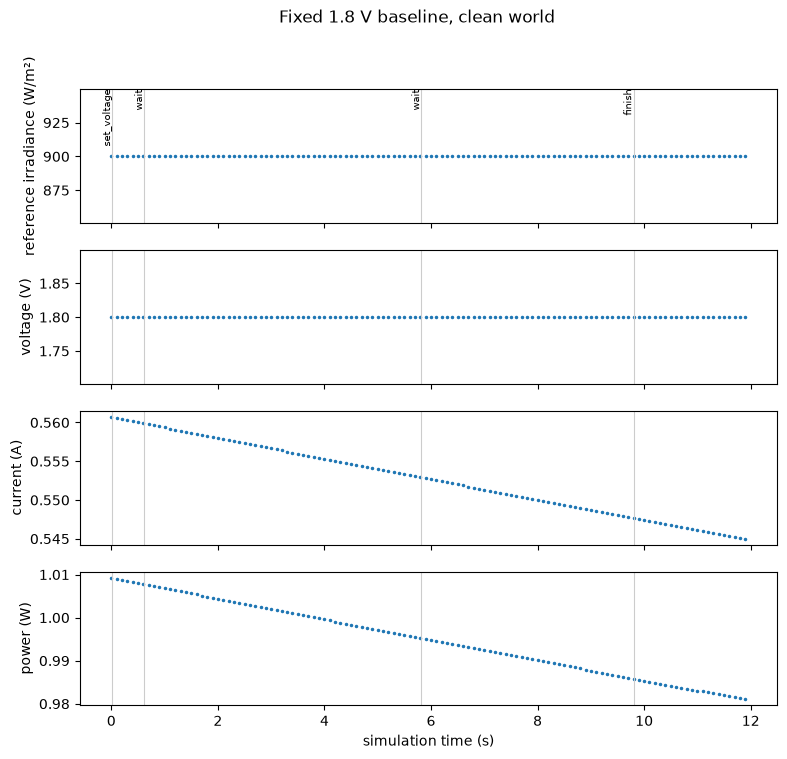

terminal reason: finished
decisions: ['set_voltage', 'wait', 'wait', 'finish']


In [7]:
def run_episode(config, policy, seed=1, render=False):
    env = PVEnv(config, enable_rendering=render)
    try:
        task, observation = env.reset(seed=seed)
        history = [observation]
        runner = PolicyRunner(policy, task)
        decisions = []
        while not history[-1].terminal:
            decision = runner.decide(tuple(history))
            if runner.last_failure:
                print("policy boundary failure:", runner.last_failure)
            decisions.append((history[-1].t_deliver_s, decision))
            history.append(env.step(decision.action))
        return task, history, decisions, env.metrics()
    finally:
        env.close()


def samples(history, channel):
    """(capture time, value) for every valid sample of one channel, in capture order."""
    points = sorted(
        (s.t_capture_s, s.value)
        for o in history for s in o.scalars
        if s.channel == channel and s.validity == "valid"
    )
    return [p[0] for p in points], [p[1] for p in points]


def power_series(history):
    """Power only from voltage and current captured at the same instant."""
    v = {s.t_capture_s: s.value for o in history for s in o.scalars
         if s.channel == "voltage_v" and s.validity == "valid"}
    i = {s.t_capture_s: s.value for o in history for s in o.scalars
         if s.channel == "current_a" and s.validity == "valid"}
    times = sorted(v.keys() & i.keys())
    return times, [v[t] * i[t] for t in times]


def plot_episode(history, decisions, title, name):
    fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
    for ax, channel, label in zip(
        axes[:3],
        ("reference_w_m2", "voltage_v", "current_a"),
        ("reference irradiance (W/m²)", "voltage (V)", "current (A)"),
    ):
        t, y = samples(history, channel)
        ax.plot(t, y, ".", ms=3)
        ax.set_ylabel(label)
    t, p = power_series(history)
    axes[3].plot(t, p, ".", ms=3)
    axes[3].set_ylabel("power (W)")
    axes[3].set_xlabel("simulation time (s)")
    for t_dec, d in decisions:
        for ax in axes:
            ax.axvline(t_dec, color="0.8", lw=0.8)
        axes[0].annotate(d.action.kind, (t_dec, axes[0].get_ylim()[1]),
                         fontsize=7, rotation=90, va="top", ha="right")
    fig.suptitle(title)
    show(fig, name)


task, history, decisions, metrics = run_episode(make_config(), FixedPolicy())
plot_episode(history, decisions, "Fixed 1.8 V baseline, clean world", "01_fixed_clean")
print("terminal reason:", history[-1].terminal_reason)
print("decisions:", [d.action.kind for _, d in decisions])

Each vertical line is a decision. The fixed policy sets 1.8 V once, waits, and
finishes with the causal question `unresolved` because it never investigated.
Read one decision record in full to see what a policy must state:

In [8]:
print(decisions[0][1].model_dump_json(indent=2))

{
  "schema_version": "1.0",
  "action": {
    "schema_version": "1.0",
    "action_id": 1,
    "timeout_s": 8.0,
    "kind": "set_voltage",
    "voltage_v": 1.8
  },
  "predictions": [],
  "hypothesis_probabilities": null,
  "unresolved_hypotheses": [
    "source_change",
    "transmission_change",
    "electrical_change",
    "thermal_change",
    "actuation_or_sensing_change"
  ],
  "evidence_refs": [
    0
  ],
  "rationale": "Hold the fixed 1.8 V baseline load."
}


## 4. Inject hidden conditions: a cloud and a shaded cell

These are **private** changes. The policy is not told about them. Watch what the
public sensors reveal and what they do not.

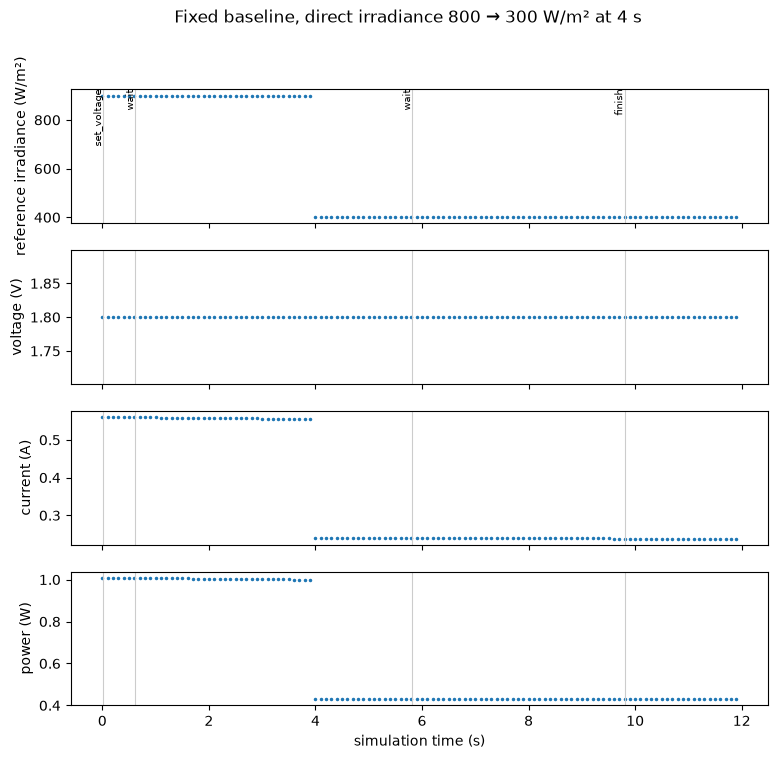

In [9]:
cloudy = make_config(cloud_at_s=4.0, cloud_dni=300.0)
task, history_cloud, decisions_cloud, _ = run_episode(cloudy, FixedPolicy())
plot_episode(history_cloud, decisions_cloud,
             "Fixed baseline, direct irradiance 800 → 300 W/m² at 4 s", "02_fixed_cloud")

The reference sensor drops together with the current, so a policy *can* tell
that less light arrived. Now shade one cell instead. The reference sensor sits
beside the panel, so it does not change; only the electrical output does.

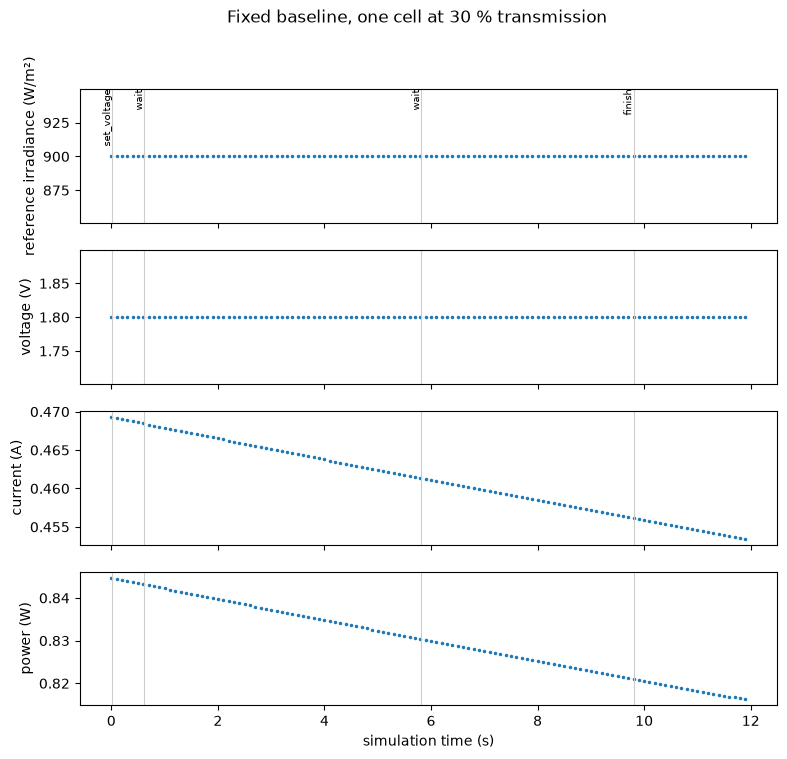

In [10]:
SHADE = [1, 1, 0.3, 1, 1, 1, 1, 1]   # cell 2 (top row, third column) at 30 % transmission
shaded = make_config(transmission=SHADE)
task, history_shade, decisions_shade, _ = run_episode(shaded, FixedPolicy())
plot_episode(history_shade, decisions_shade,
             "Fixed baseline, one cell at 30 % transmission", "03_fixed_shaded")

In [11]:
def mean_power(history, after_s=2.0):
    t, p = power_series(history)
    values = [pi for ti, pi in zip(t, p) if ti >= after_s]
    return sum(values) / len(values)

print(f"mean power after 2 s   clean: {mean_power(history):.3f} W"
      f"   cloud: {mean_power(history_cloud, after_s=5.0):.3f} W"
      f"   shaded: {mean_power(history_shade):.3f} W")

mean power after 2 s   clean: 0.993 W   cloud: 0.430 W   shaded: 0.828 W


Lower power with an unchanged reference reading is exactly the ambiguous
situation the programme is about: the numbers say *something* reduced output,
not *what*. Images, a probe or an outside question could separate the causes.

## 5. Camera data collection

The camera is a 640×480 RGB sensor on a three-axis rig (slide, yaw, pitch).
Two actions produce frames: `capture_rgb` takes one frame where the camera is,
and `move_camera` with `capture_after_settle=True` moves, waits for the servos
to settle, and then captures. Frames arrive inside the observation as PNG bytes
with exposure window, capture time and the calibration they were taken with.
Each frame draws on the `rgb_frames` budget and costs 0.1 utility units.

The helper below drives the rig by hand: a home frame, then three moves. It
returns the full history so we can also watch the encoders during the moves.

move to slide=+0.12 m yaw=+0.26 rad pitch=+0.00 rad -> completed at 3.57 s, frames so far 2, rgb budget left 18
move to slide=+0.12 m yaw=+0.26 rad pitch=+0.25 rad -> completed at 5.12 s, frames so far 3, rgb budget left 17


move to slide=-0.12 m yaw=-0.26 rad pitch=+0.00 rad -> completed at 10.72 s, frames so far 4, rgb budget left 16


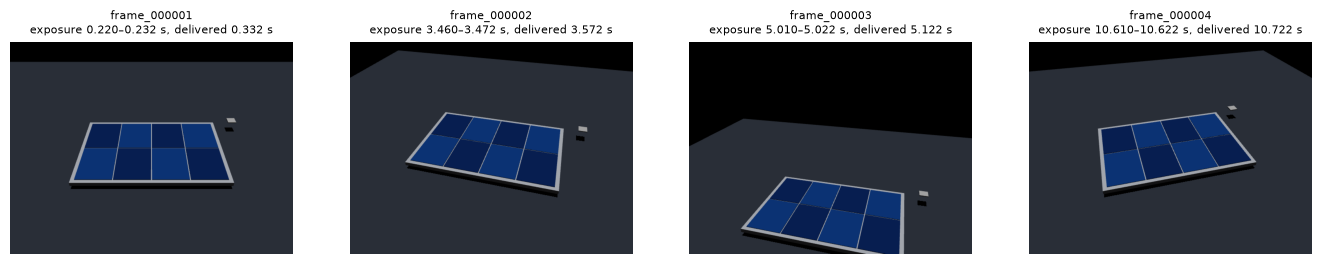

one frame record (without the image bytes and the K matrix):
{'t_capture_s': 0.226, 't_deliver_s': 0.332, 'validity': 'valid', 'frame_id': 'frame_000001', 'camera_id': 'agent_rgb', 'width': 640, 'height': 480, 'encoding': 'png_rgb8', 'calibration_id': 'nominal_v1', 'exposure': {'duration_s': 0.012, 'approximation': 'midpoint_snapshot'}, 't_start_s': 0.22, 't_end_s': 0.232}


In [12]:
def frame_image(frame):
    """Decode one RGBSample into a (480, 640, 3) uint8 array."""
    return np.array(Image.open(io.BytesIO(base64.b64decode(frame.png_base64))))


def frames_in(history):
    return [f for o in history for f in o.rgb if f.validity == "valid"]


def encoder_series(history):
    rows = sorted(
        (e.t_capture_s, e.slide_m, e.yaw_rad, e.pitch_rad)
        for o in history for e in o.encoders if e.validity == "valid"
    )
    return np.array(rows) if rows else np.zeros((0, 4))


def collect_views(config, poses, seed=1):
    """Home frame, then one move-and-capture per pose. Returns (task, history, commands)."""
    env = PVEnv(config, enable_rendering=True)
    try:
        task, observation = env.reset(seed=seed)
        history, commands = [observation], []
        action_id = 1
        history.append(env.step({"schema_version": "1.0", "action_id": action_id,
                                 "kind": "capture_rgb", "timeout_s": 2.0}))
        commands.append((history[-2].t_deliver_s, "capture_rgb", None))
        for slide, yaw, pitch in poses:
            action_id += 1
            history.append(env.step({"schema_version": "1.0", "action_id": action_id,
                                     "kind": "move_camera", "timeout_s": 10.0,
                                     "slide_m": slide, "yaw_rad": yaw, "pitch_rad": pitch,
                                     "capture_after_settle": True}))
            commands.append((history[-2].t_deliver_s, "move_camera", (slide, yaw, pitch)))
            terminal = [f for f in history[-1].feedback if f.t_terminal_s is not None]
            print(f"move to slide={slide:+.2f} m yaw={yaw:+.2f} rad pitch={pitch:+.2f} rad -> "
                  f"{terminal[-1].code} at {terminal[-1].t_terminal_s:.2f} s, "
                  f"frames so far {len(frames_in(history))}, "
                  f"rgb budget left {history[-1].remaining_budgets.rgb_frames}")
        return task, history, commands
    finally:
        env.close()


side_yaw = math.atan(0.12 / 0.45)   # look back at the panel centre from the side
POSES = [(0.12, side_yaw, 0.0), (0.12, side_yaw, 0.25), (-0.12, -side_yaw, 0.0)]

if RENDER:
    task_cam, history_cam, commands_cam = collect_views(make_config(horizon_s=20.0), POSES)
    frames = frames_in(history_cam)
    fig, axes = plt.subplots(1, len(frames), figsize=(4.2 * len(frames), 3.6))
    for ax, frame in zip(np.atleast_1d(axes), frames):
        ax.imshow(frame_image(frame))
        ax.set_title(f"{frame.frame_id}\nexposure {frame.t_start_s:.3f}–{frame.t_end_s:.3f} s, "
                     f"delivered {frame.t_deliver_s:.3f} s", fontsize=8)
        ax.axis("off")
    show(fig, "05_camera_views")
    print("one frame record (without the image bytes and the K matrix):")
    print({k: v for k, v in frames[0].model_dump().items() if k not in ("png_base64", "k")})
else:
    print("skipped: rendering is not available in this session")

### Monitoring the actuator: command versus measured pose

The encoders stream at 20 Hz while the rig moves. The plot shows each axis
against time, the commanded targets as dashed lines, and the instants at which
frames were exposed. The slide runs at 0.05 m/s, so a 0.24 m traverse takes
about five seconds of episode time: moving the camera is not free. The
completed move feedback carries the encoder sample that confirms the pose,
just as the set-voltage feedback carried a voltage sample.

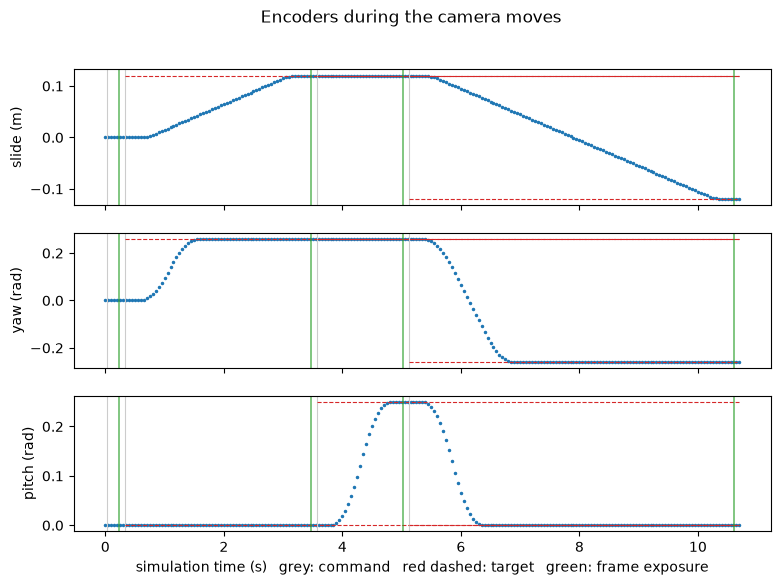

move 1 completed at 3.57 s; confirming encoder sample: slide=0.1200 m yaw=0.2606 rad pitch=0.0000 rad, age 0.122 s


In [13]:
if RENDER:
    enc = encoder_series(history_cam)
    fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
    for k, (ax, label) in enumerate(zip(axes, ("slide (m)", "yaw (rad)", "pitch (rad)"))):
        ax.plot(enc[:, 0], enc[:, k + 1], ".", ms=3)
        ax.set_ylabel(label)
        for t_cmd, kind, target in commands_cam:
            ax.axvline(t_cmd, color="0.8", lw=0.8)
            if target is not None:
                ax.hlines(target[k], t_cmd, enc[-1, 0], colors="C3", linestyles="--", lw=0.8)
        for frame in frames:
            ax.axvline(frame.t_capture_s, color="C2", lw=1.2, alpha=0.7)
    axes[-1].set_xlabel("simulation time (s)   grey: command   red dashed: target   green: frame exposure")
    fig.suptitle("Encoders during the camera moves")
    show(fig, "06_camera_encoders")
    moves = [f for o in history_cam for f in o.feedback
             if f.code == "completed" and f.commanded_target.kind == "move_camera"]
    m = moves[0].measured_confirmation[0]
    print(f"move 1 completed at {moves[0].t_terminal_s:.2f} s; confirming encoder sample: "
          f"slide={m.sample.slide_m:.4f} m yaw={m.sample.yaw_rad:.4f} rad pitch={m.sample.pitch_rad:.4f} rad, "
          f"age {m.age_s:.3f} s")
else:
    print("skipped: rendering is not available in this session")

### What the camera can and cannot see

Take the same home frame in three worlds: clean, cloudy (direct irradiance
300 W/m² from the start) and one cell shaded at 30 % transmission.

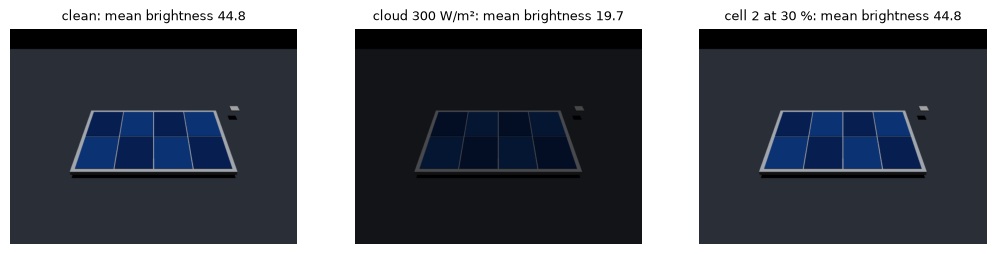

largest pixel difference, clean vs shaded: 0


In [14]:
def home_frame(config):
    _, hist, _ = collect_views(config, poses=[])
    return frame_image(frames_in(hist)[0])


if RENDER:
    worlds = [("clean", make_config()), ("cloud 300 W/m²", make_config(dni=300.0)),
              ("cell 2 at 30 %", make_config(transmission=SHADE))]
    images = [(label, home_frame(cfg)) for label, cfg in worlds]
    fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.6))
    for ax, (label, img) in zip(axes, images):
        ax.imshow(img)
        ax.set_title(f"{label}: mean brightness {img.mean():.1f}", fontsize=9)
        ax.axis("off")
    show(fig, "07_camera_worlds")
    diff = np.abs(images[0][1].astype(int) - images[2][1].astype(int)).max()
    print("largest pixel difference, clean vs shaded:", diff)
else:
    print("skipped: rendering is not available in this session")

The cloud is visible: the scene lighting scales with direct and diffuse
irradiance, so the whole frame darkens. The shaded cell is **not** visible: in
this build the cell colours are a fixed checker pattern, independent of the
hidden transmission, and the shading acts only on the electrical model. The
only visual fixtures the simulator has today are the M2 view screens, which
block the camera's view without shading the panel.

That gap is deliberate and it is where the module's minimal goal starts. A camera is
only worth its cost if shading, soiling or an object on the panel changes the
picture, and if the agent has a way to turn that picture into a hypothesis
about which cells are affected. Adding visible, physically consistent shading
to the scene (image and electrical model driven by the same cause) is the
first thing the demonstration needs.

## 6. A policy that investigates: probe, select, verify, finish

`ScanPolicy` (B1) captures two camera views and then probes three voltages. The
subclass below drops the camera moves so it also runs headless. It selects the
highest measured power, sets that voltage unless it is already applied, waits
for a fresh confirming measurement and finishes. The verify and finish stages
are B1's own code.

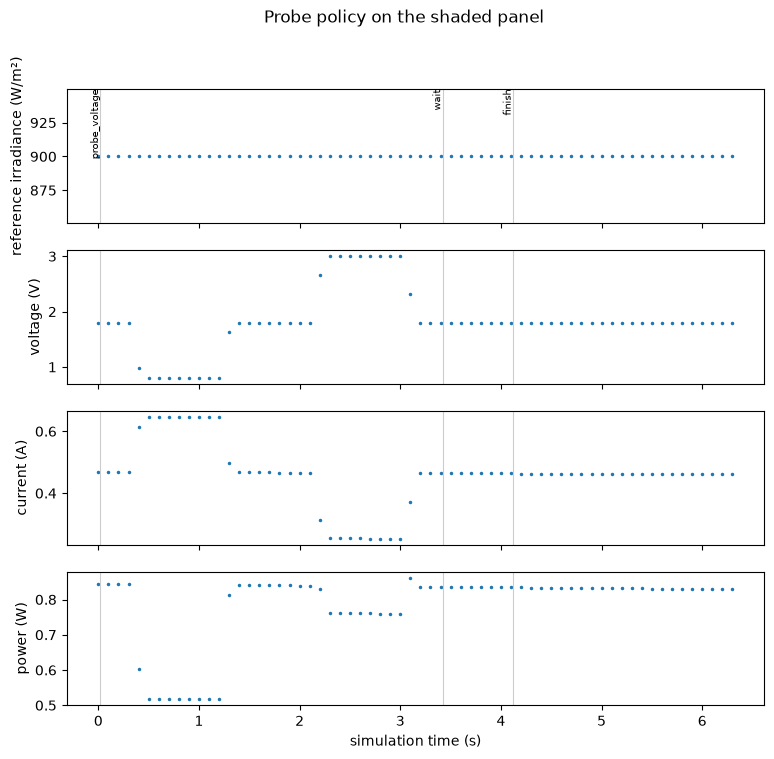

decisions:         ['probe_voltage', 'wait', 'finish']
chosen voltage (V): 1.8
terminal reason:    finished


In [15]:
class ProbePolicy(ScanPolicy):
    """B1 without the two camera moves.

    One extra rule: a probe restores the voltage it started from, and the
    completed probe feedback carries the measurement that confirms the
    restoration. If the best measured point is the one already applied, a new
    set command would be redundant (the simulator rejects it), so verify instead.
    """

    def act(self, history):
        if self.stage == "start":
            self.stage = "probe"
            return self._emit(
                history, "probe_voltage",
                "Measure three candidate voltages with a settled dwell.",
                voltages_v=(0.8, 1.8, 3.0), dwell_s=0.5,
            )
        if self.stage == "probe":
            feedback = self._completion(history)
            if feedback is None or feedback.code != "completed":
                return self._stop(history, "The probe did not complete.")
            self.chosen_voltage = self._select_probe_point(history, feedback)
            if self.chosen_voltage is None:
                return self._stop(history, "The probe lacks matched V/I for every point.")
            if self._voltage_confirmed(feedback, self.chosen_voltage):
                self.verification_after_s = feedback.t_terminal_s
                self.stage = "verify"
                return self._emit(
                    history, "wait",
                    "The best measured point is already applied; collect fresh V/I to verify it.",
                    evidence_refs=self.probe_evidence_refs, duration_s=0.5, timeout_s=1.0,
                )
            self.stage = "set"
            return self._emit(
                history, "set_voltage",
                "Select the scheduled point with the greatest measured V times I.",
                evidence_refs=self.probe_evidence_refs, voltage_v=self.chosen_voltage,
            )
        return super().act(history)


policy = ProbePolicy()
task, history_probe, decisions_probe, metrics_probe = run_episode(shaded, policy)
plot_episode(history_probe, decisions_probe,
             "Probe policy on the shaded panel", "08_probe_shaded")
print("decisions:        ", [d.action.kind for _, d in decisions_probe])
print("chosen voltage (V):", policy.chosen_voltage)
print("terminal reason:   ", history_probe[-1].terminal_reason)

Look at the feedback of the probe action. Each dwell point reports the matched
voltage and current that were actually measured, and the policy's choice cites
the observation sequence numbers it relied on (`evidence_refs`). That is the
evidence trail the evaluator checks.

In [16]:
for _, d in decisions_probe:
    print(f"{d.action.kind:14s} evidence_refs={d.evidence_refs}  rationale={d.rationale}")

probe_voltage  evidence_refs=(0,)  rationale=Measure three candidate voltages with a settled dwell.
wait           evidence_refs=(1,)  rationale=The best measured point is already applied; collect fresh V/I to verify it.
finish         evidence_refs=(2,)  rationale=Fresh V/I verifies the operating point; causal diagnosis remains unresolved.


### The same loop with the camera in it

With rendering on, put B1's two camera stages back in front of the probe: home
frame, side frame, probe, select, verify, finish. The decision timeline now
shows the two frames and the time the camera move consumed before the probe
even started. (B1 itself would stop here, because it always re-sends the chosen
voltage and the simulator rejects a redundant setpoint; the subclass keeps the
restoration check from `ProbePolicy`.)

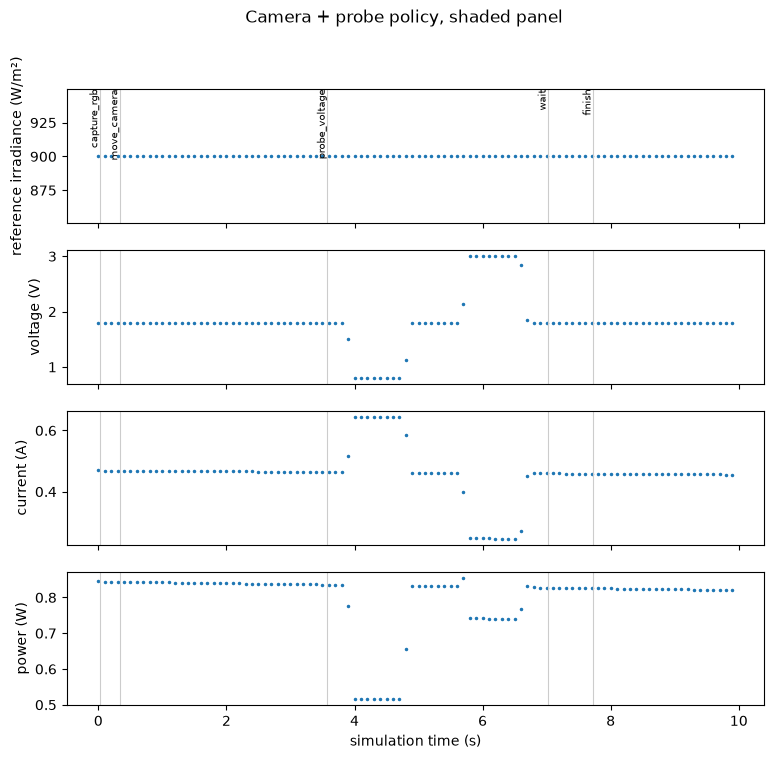

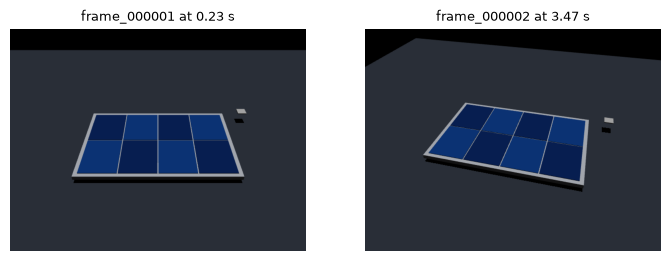

decisions: ['capture_rgb', 'move_camera', 'probe_voltage', 'wait', 'finish']
chosen voltage (V): 1.8 | terminal: finished | rgb frames used: 2 | energy (J): 7.906


In [17]:
class CameraProbePolicy(ProbePolicy):
    """B1's home and side frames, then ProbePolicy's probe, select, verify, finish."""

    def act(self, history):
        if self.stage == "start":
            if "rgb" not in self.task.sensors:
                return self._stop(history, "This policy needs the camera; use ProbePolicy headless.")
            self.stage = "home"
            return self._emit(history, "capture_rgb", "Capture the initial home view.")
        if self.stage in ("home", "side"):
            return ScanPolicy.act(self, history)   # B1's own camera stages; they end by emitting the probe
        return super().act(history)


if RENDER:
    scan = CameraProbePolicy()
    task, history_scan, decisions_scan, metrics_scan = run_episode(
        make_config(horizon_s=16.0, transmission=SHADE), scan, render=True)
    plot_episode(history_scan, decisions_scan, "Camera + probe policy, shaded panel", "09_scan_shaded")
    frames_scan = frames_in(history_scan)
    fig, axes = plt.subplots(1, len(frames_scan), figsize=(4.2 * len(frames_scan), 3.4))
    for ax, frame in zip(np.atleast_1d(axes), frames_scan):
        ax.imshow(frame_image(frame))
        ax.set_title(f"{frame.frame_id} at {frame.t_capture_s:.2f} s", fontsize=9)
        ax.axis("off")
    show(fig, "10_scan_frames")
    print("decisions:", [d.action.kind for _, d in decisions_scan])
    print("chosen voltage (V):", scan.chosen_voltage, "| terminal:", history_scan[-1].terminal_reason,
          "| rgb frames used:", metrics_scan["rgb_frames"], "| energy (J):", round(metrics_scan["pv_energy_j"], 3))
else:
    print("skipped: rendering is not available in this session")

## 7. Monitoring: watch continuously, investigate only when something is unexplained

A real plant is not investigated on a schedule; it is **monitored**, and an
investigation is triggered by a change the monitor cannot explain. The policy
below does that in the simplest honest way:

- it waits in one-second chunks and, after each, looks at the last half second
  of matched power `P` and reference irradiance `G`;
- it carries a **commissioned baseline** `(P0, G0)` measured on the clean plant,
  which is prior knowledge the agent brings, not something the simulator gives;
- if `P` is well below `P0`, it asks whether the reference irradiance explains
  it: at a fixed voltage, power scales roughly with irradiance, so the expected
  power is `P0 · G / G0`;
- a drop that is explained is **logged** and monitoring continues; a drop that
  is not explained **triggers the probe** from section 6, and the finish then
  states hypothesis probabilities that favour a transmission change.

Everything the monitor uses is in the public history. The verdicts it writes
into its rationale are what an evaluator will later check against hidden truth.

In [18]:
class MonitorPolicy(ProbePolicy):
    """Hold, watch P and G_ref, investigate only an unexplained drop."""

    def __init__(self, commissioned, drop=0.9, window_s=0.5, chunk_s=1.0):
        self.P0, self.G0 = commissioned
        self.drop, self.window_s, self.chunk_s = drop, window_s, chunk_s
        self.log = []          # (t, P, G, expected P, verdict)
        self.triggered = False

    def reset(self, task):
        super().reset(task)
        self.stage = "monitor"

    def _recent(self, t, y, t_end):
        values = [yi for ti, yi in zip(t, y) if ti >= t_end - self.window_s]
        return sum(values) / len(values) if values else None

    def act(self, history):
        if self.stage == "verify" and self.triggered:
            return self._finish_with_belief(history)
        if self.stage != "monitor":
            return super().act(history)
        if history[-1].terminal:
            return self._stop(history, "Episode already terminal.")
        feedback = self._completion(history)
        if self.pending is not None and (feedback is None or feedback.code != "completed"):
            return self._stop(history, "The previous wait did not complete.")
        now = history[-1].t_deliver_s
        P = self._recent(*power_series(history), now)
        G = self._recent(*samples(history, "reference_w_m2"), now)
        if P is not None and G is not None:
            expected = self.P0 * G / self.G0
            if P < self.drop * self.P0 and P < self.drop * expected:
                verdict = "UNEXPLAINED drop: investigate"
            elif P < self.drop * self.P0:
                verdict = "drop explained by irradiance: keep monitoring"
            else:
                verdict = "nominal"
            self.log.append((now, P, G, expected, verdict))
            if verdict.startswith("UNEXPLAINED"):
                self.triggered = True
                self.stage = "start"          # hand over to the probe schedule
                return super().act(history)
        remaining = history[-1].remaining_budgets.time_s
        if remaining <= 2.5:
            self.stage = "finished"
            return self._emit(history, "finish", "Monitoring ended without an unexplained change.",
                              resolution="unresolved", timeout_s=2.0)
        duration = min(self.chunk_s, remaining - 2.4)
        return self._emit(history, "wait",
                          f"Monitor: P={P and round(P, 3)} W, G={G and round(G, 0)} W/m².",
                          duration_s=duration, timeout_s=duration + 0.1)

    def _finish_with_belief(self, history):
        """Like ScanPolicy's finish, but with a stated belief over the hypothesis classes."""
        refs = self._verification_refs(history)
        if not refs:
            return self._stop(history, "No newer matched V/I verifies the selected operating point.")
        # Reference irradiance unchanged, power low, probe found no better point:
        # favour a transmission change; leave mass on the alternatives.
        weights = {"transmission_change": 0.6, "electrical_change": 0.2, "thermal_change": 0.1,
                   "source_change": 0.05, "actuation_or_sensing_change": 0.05}
        labels = self.task.hypothesis_classes
        total = sum(weights.get(h, 0.0) for h in labels)
        action = ACTION_ADAPTER.validate_python(dict(
            schema_version="1.0", action_id=self.next_action_id, kind="finish",
            timeout_s=2.0, resolution="unresolved"))
        decision = Decision(
            schema_version="1.0", action=action, predictions=(),
            hypothesis_probabilities=tuple(
                HypothesisProbability(hypothesis=h, probability=weights.get(h, 0.0) / total) for h in labels),
            unresolved_hypotheses=(),
            evidence_refs=tuple(sorted(set(self.probe_evidence_refs) | set(refs))),
            rationale="Fresh V/I verifies the operating point. Reference irradiance was unchanged "
                      "while power fell and no better voltage exists: a transmission change is most "
                      "likely, but the probe cannot say which cell, so the question stays open.",
        )
        validate_decision_context(decision, self.task, history)
        self.next_action_id += 1
        self.pending = action
        self.stage = "finished"
        return decision


# the commissioned baseline: measured once on the clean plant at the nominal voltage
P0 = mean_power(history, after_s=1.0)
_, g_clean = samples(history, "reference_w_m2")
G0 = sum(g_clean) / len(g_clean)
print(f"commissioned baseline: P0={P0:.3f} W at G0={G0:.0f} W/m²")

scenarios = [
    ("clean", make_config(horizon_s=14.0)),
    ("cloud at 4 s", make_config(horizon_s=14.0, cloud_at_s=4.0, cloud_dni=300.0)),
    ("shaded cell", make_config(horizon_s=14.0, transmission=SHADE)),
]
monitor_runs = []
for label, cfg in scenarios:
    monitor = MonitorPolicy(commissioned=(P0, G0))
    _, hist, decs, mets = run_episode(cfg, monitor)
    monitor_runs.append((label, hist, decs, mets, monitor))
    print(f"\n== {label} ==  decisions: {[d.action.kind for _, d in decs]}  terminal: {hist[-1].terminal_reason}")
    for t, P, G, expected, verdict in monitor.log:
        print(f"  t={t:5.2f} s  P={P:.3f} W  G={G:4.0f}  expected={expected:.3f} W  -> {verdict}")
    final = decs[-1][1]
    if final.hypothesis_probabilities:
        print("  finish states:", {h.hypothesis: round(h.probability, 2) for h in final.hypothesis_probabilities})

commissioned baseline: P0=0.994 W at G0=900 W/m²



== clean ==  decisions: ['wait', 'wait', 'wait', 'wait', 'wait', 'wait', 'wait', 'wait', 'wait', 'wait', 'finish']  terminal: finished
  t= 0.02 s  P=1.009 W  G= 900  expected=0.994 W  -> nominal
  t= 1.22 s  P=1.007 W  G= 900  expected=0.994 W  -> nominal
  t= 2.42 s  P=1.004 W  G= 900  expected=0.994 W  -> nominal
  t= 3.62 s  P=1.001 W  G= 900  expected=0.994 W  -> nominal
  t= 4.82 s  P=0.998 W  G= 900  expected=0.994 W  -> nominal
  t= 6.02 s  P=0.995 W  G= 900  expected=0.994 W  -> nominal
  t= 7.22 s  P=0.992 W  G= 900  expected=0.994 W  -> nominal
  t= 8.42 s  P=0.990 W  G= 900  expected=0.994 W  -> nominal
  t= 9.62 s  P=0.987 W  G= 900  expected=0.994 W  -> nominal
  t=10.82 s  P=0.984 W  G= 900  expected=0.994 W  -> nominal
  t=11.80 s  P=0.982 W  G= 900  expected=0.994 W  -> nominal



== cloud at 4 s ==  decisions: ['wait', 'wait', 'wait', 'wait', 'wait', 'wait', 'wait', 'wait', 'wait', 'wait', 'finish']  terminal: finished
  t= 0.02 s  P=1.009 W  G= 900  expected=0.994 W  -> nominal
  t= 1.22 s  P=1.007 W  G= 900  expected=0.994 W  -> nominal
  t= 2.42 s  P=1.004 W  G= 900  expected=0.994 W  -> nominal
  t= 3.62 s  P=1.001 W  G= 900  expected=0.994 W  -> nominal
  t= 4.82 s  P=0.432 W  G= 400  expected=0.442 W  -> drop explained by irradiance: keep monitoring
  t= 6.02 s  P=0.431 W  G= 400  expected=0.442 W  -> drop explained by irradiance: keep monitoring
  t= 7.22 s  P=0.431 W  G= 400  expected=0.442 W  -> drop explained by irradiance: keep monitoring
  t= 8.42 s  P=0.430 W  G= 400  expected=0.442 W  -> drop explained by irradiance: keep monitoring
  t= 9.62 s  P=0.430 W  G= 400  expected=0.442 W  -> drop explained by irradiance: keep monitoring
  t=10.82 s  P=0.429 W  G= 400  expected=0.442 W  -> drop explained by irradiance: keep monitoring
  t=11.80 s  P=0.42


== shaded cell ==  decisions: ['probe_voltage', 'wait', 'finish']  terminal: finished
  t= 0.02 s  P=0.845 W  G= 900  expected=0.994 W  -> UNEXPLAINED drop: investigate
  finish states: {'source_change': 0.05, 'transmission_change': 0.6, 'electrical_change': 0.2, 'thermal_change': 0.1, 'actuation_or_sensing_change': 0.05}


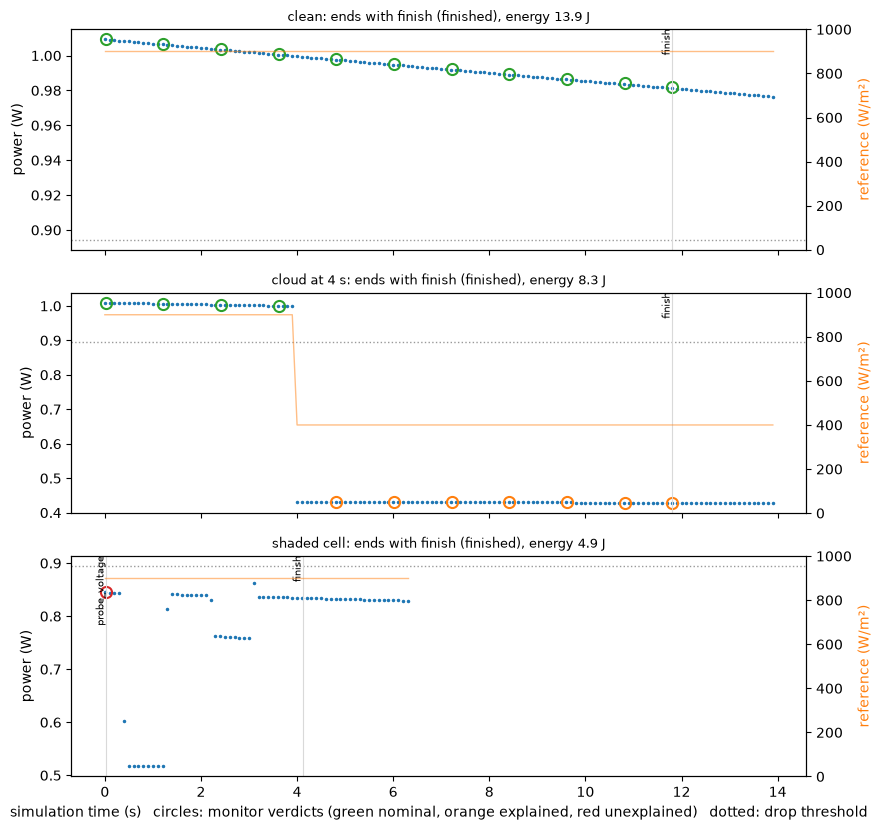

In [19]:
fig, axes = plt.subplots(len(monitor_runs), 1, figsize=(9, 2.8 * len(monitor_runs)), sharex=True)
for ax, (label, hist, decs, mets, monitor) in zip(axes, monitor_runs):
    t, p = power_series(hist)
    ax.plot(t, p, ".", ms=3)
    tg, g = samples(hist, "reference_w_m2")
    ax2 = ax.twinx()
    ax2.plot(tg, g, "-", color="C1", lw=1, alpha=0.5)
    ax2.set_ylim(0, 1000)
    ax2.set_ylabel("reference (W/m²)", color="C1")
    ax.axhline(monitor.drop * P0, color="0.6", ls=":", lw=1)
    for tt, P, G, expected, verdict in monitor.log:
        colour = {"n": "C2", "d": "C1", "U": "C3"}[verdict[0]]
        ax.plot(tt, P, "o", color=colour, ms=8, mfc="none", mew=1.5)
    for t_dec, d in decs:
        if d.action.kind != "wait":
            ax.axvline(t_dec, color="0.85", lw=0.8)
            ax.annotate(d.action.kind, (t_dec, ax.get_ylim()[1]), fontsize=7, rotation=90, va="top", ha="right")
    ax.set_ylabel("power (W)")
    ax.set_title(f"{label}: ends with {decs[-1][1].action.kind} ({hist[-1].terminal_reason}), "
                 f"energy {mets['pv_energy_j']:.1f} J", fontsize=9)
axes[-1].set_xlabel("simulation time (s)   circles: monitor verdicts (green nominal, orange explained, "
                    "red unexplained)   dotted: drop threshold")
fig.tight_layout()
show(fig, "11_monitor")

On the clean plant the monitor never triggers. Under the cloud the power falls
but so does the reference irradiance, so the verdict is "explained" and the
probe is not spent. On the shaded plant the reference is unchanged, the drop is
unexplained at the very first check (the fault is present from the start), and
the monitor hands over to the probe schedule, then finishes with a stated belief.

Two honest limitations, both worth fixing in a student project. The linear
`P0 · G / G0` expectation is crude; a calibrated PV model would set a tighter
threshold and detect smaller faults. And the probe confirms that no better
operating point exists, but it does not identify *which* cell is shaded; that
is what a camera with visible shading, or a per-substring measurement, would
add.

## 8. Metrics and budgets

`env.metrics()` is the evaluator's ledger: energy actually produced, resources
used, whether the verification tail completed, and the final hidden operating
point. Compare the fixed, probing and monitoring policies on the same shaded
world.

In [20]:
_, _, _, metrics_fixed = run_episode(shaded, FixedPolicy())
_, _, _, metrics_monitor = run_episode(shaded, MonitorPolicy(commissioned=(P0, G0)))
keys = ["pv_energy_j", "voltage_points", "rgb_frames", "decisions", "elapsed_s",
        "verification_tail_complete", "terminal_reason", "synthetic_dimensionless_utility"]


def fmt(value):
    return str(round(value, 4) if isinstance(value, float) else value)


print(f"{'metric':36s}{'fixed':>14s}{'probe':>14s}{'monitor':>14s}")
for k in keys:
    print(f"{k:36s}{fmt(metrics_fixed[k]):>14s}{fmt(metrics_probe[k]):>14s}{fmt(metrics_monitor[k]):>14s}")
print("\nremaining budgets at the end (probe policy):")
print(history_probe[-1].remaining_budgets.model_dump())

metric                                       fixed         probe       monitor
pv_energy_j                                 9.9612        4.9407        4.9407
voltage_points                                   1             3             3
rgb_frames                                       0             0             0
decisions                                        4             3             3
elapsed_s                                     12.0          6.32          6.32
verification_tail_complete                    True          True          True
terminal_reason                           finished      finished      finished
synthetic_dimensionless_utility             -0.034       -0.5177       -0.5177

remaining budgets at the end (probe policy):
{'time_s': 5.68, 'rgb_frames': 20, 'voltage_points': 9, 'help_requests': 1, 'decisions': 97, 'slide_path_m': 1.5, 'angular_path_rad': 6.0}


A probe costs energy while it visits the low and high voltages, and a camera
move costs time and utility. Whether the information they buy is worth that
cost is a question to answer by experiment, not by assumption. That is the
whole method of this project.

## 9. Your turn: a policy template

Rules the runner enforces (see README section 7): only public records, strictly
increasing `action_id`, hypotheses from the declared list, a 2 s verification
tail before `finish`, and read the feedback before believing a setpoint.

Ideas to try, in order of difficulty:

1. Compare the clean and shaded worlds using only the probe results. Which of the
   three measured powers changes most?
2. Tighten the monitor: estimate `P0` and `G0` from the first two seconds of
   the episode instead of a commissioned value, and see what that costs you when
   the fault is present from the start.
3. Give the monitor a second trigger on the camera: capture a frame every few
   seconds and raise an event when the mean brightness changes while the
   reference irradiance does not. (In this build that never fires for shading:
   section 5 shows why.)
4. Run the same policies on `configs/dev.toml`, where sensors are noisy and
   samples can be stale or missing. Does the monitor false-alarm? Does it still
   verify?
5. Use `Decision.predictions` to state, before a `set_voltage`, what current you
   expect afterwards. The evaluator scores those predictions.

The template below holds, waits, and finishes; replace the body of `act`.

In [21]:
class MyPolicy(PublicBaseline):
    def act(self, history):
        if history and history[-1].terminal:
            return self._stop(history, "Episode already terminal.")
        remaining = history[-1].remaining_budgets.time_s if history else self.task.horizon_s
        if self.stage == "start":
            self.stage = "holding"
            return self._emit(history, "set_voltage", "Hold the nominal point.", voltage_v=1.8)
        feedback = self._completion(history)
        if feedback is None or feedback.code != "completed":
            return self._stop(history, "Previous action did not complete.")
        if remaining <= 2.5:
            self.stage = "finished"
            return self._emit(history, "finish", "Done; cause not investigated.",
                              resolution="unresolved", timeout_s=2.0)
        duration = min(3.0, remaining - 2.4)
        return self._emit(history, "wait", "Collect evidence.",
                          duration_s=duration, timeout_s=duration + 0.1)


task, history_mine, decisions_mine, metrics_mine = run_episode(shaded, MyPolicy())
print("decisions:", [d.action.kind for _, d in decisions_mine],
      "| energy (J):", round(metrics_mine["pv_energy_j"], 3),
      "| terminal:", history_mine[-1].terminal_reason)

decisions: ['set_voltage', 'wait', 'wait', 'wait', 'finish'] | energy (J): 9.961 | terminal: finished


## Where to go next

- `docs/paired-investigation.md`: the R versus A comparison and how to rerun it.
- `docs/investigation-workflow.md`: the richer `AgentContext` interface with world
  belief, self model and information requests. This is where an LLM agent plugs in.
- `output/workflow/paired-03/paired-public.html`: open in a browser to replay a
  recorded investigation with synchronised plots and 3D.
- The plain-language overview (`output/pdf/Agentic_PV_Overview_Plain_Language_2026-10-30.pdf`)
  and the programme brief, Case A and Case B: the minimal goal (simulator, agent,
  bench prototype) and the stretch goals beyond it. Section 5 above shows the first gap.
- `notebooks/multimodality_and_agent_loop.ipynb`: the ideas behind the mechanics shown here.